In [1]:
import pandas as pd
import pygit2
import sqlite3
import email
import re
from pygit2 import Repository

In [2]:
from analysis import find_start_message_id

In [3]:
%matplotlib inline
import matplotlib.pyplot as plt
plt.style.use('ggplot')
plt.rcParams['figure.figsize'] = (15, 5)
plt.rcParams['font.family'] = 'sans-serif'

In [4]:
con = sqlite3.connect('./emails.db')
con.row_factory = sqlite3.Row
cur = con.cursor()

In [5]:
# Find all commits with an entry in the amlog
query = """
SELECT amlog.commit_id, amlog.message_id, merge_time, list_messages.subject as final_subject
FROM git_commits
INNER JOIN amlog
    ON amlog.commit_id = git_commits.commit_id
LEFT JOIN list_messages ON (list_messages.message_id = amlog.message_id)
;
"""
commit_list = pd.read_sql(query, con)

In [6]:
def match_to_original_message(df):
    messages = []
    num_missing = 0
    for items in df.to_dict('records'):
        try:
            data = dict(find_start_message_id(cur, items['message_id']))
            data.update(items)
            messages.append(data)
        except:
            num_missing += 1
    print(f"warning: didn't find {num_missing} messages")

    df = pd.DataFrame(messages)
    # Clean up the columns a bit
    df['date'] = pd.to_datetime(df['date'] * 1000000000)
    df['merge_time'] = pd.to_datetime(df['merge_time'] * 1000000000)
    df = df.rename(columns={'date': 'start_time', 'subject': 'first_subject'})
    return df

In [7]:
def guess_iterations(subject):
    if 'PATCH v' not in subject:
        # this may be wildly optimistic, don't know
        # but from quick spot check it seems okay
        return 1
    matches = re.findall(r'PATCH v(\d+)', subject)
    if matches is not None and len(matches) > 0:
        return matches[0]

This `df` is the main dataset we'll draw the rest of the graphs from.

In [8]:
df = match_to_original_message(commit_list)
df['iterations'] = df['final_subject'].map(guess_iterations)

Here's one example row:

In [9]:
df[3:4]

,message_id,first_subject,start_time,in_reply_to,commit_id,merge_time,final_subject,iterations
3,<CAOJ8FdeyJp4ZOfp99DBSp4brWzngdqzrkSY36ByEh=4U...,[PATCH] oss-fuzz: set a gitdir in the commit-g...,2026-10-24 18:50:42,NaN,99ecb6ca8b32aeee47fcb2e76c2b7658f58a30f2,2026-11-09 01:10:44,[PATCH] oss-fuzz: set a gitdir in the commit-g...,1


# Median time to merge each year

Some issues with this:

- Some commits aren't matched up properly with their original patch email, because sometimes when people send the v2 they don't set the In-Reply-To to the previous version
- Some commits can't be matched to anything on the mailing list at all for reasons that I haven't fully investigated. For example the gitk and gitgui commits.

In [10]:
df['time_to_merge'] = (df['merge_time'] - df['start_time'])

<Axes: title={'center': 'Median time to merge'}, xlabel='year', ylabel='days'>

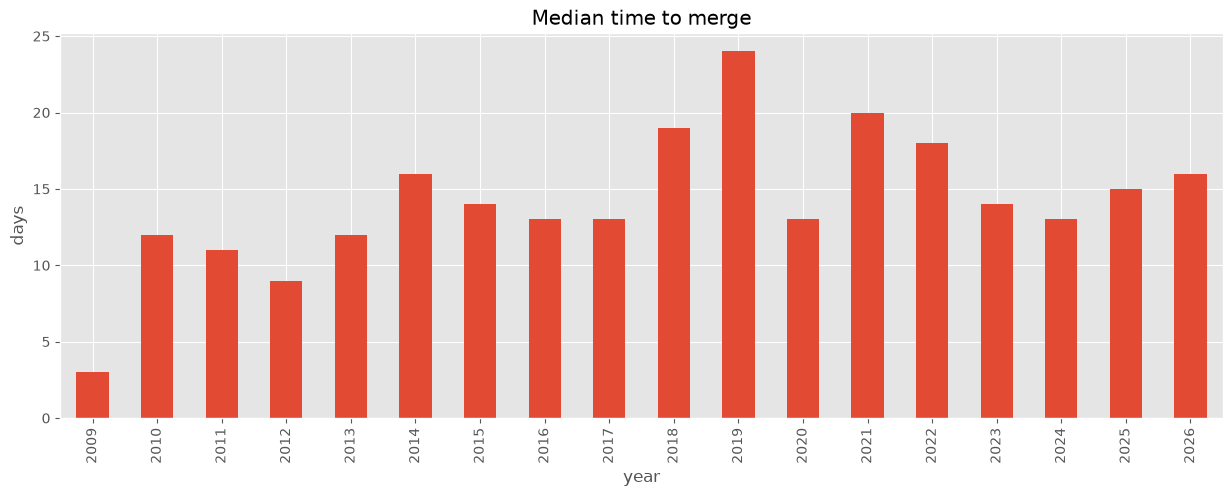

In [11]:
median = (
    df[['merge_time', 'time_to_merge']]
        .groupby(df.merge_time.dt.year)
        .aggregate('time_to_merge')
        .median())
median.dt.days.plot(kind='bar', title="Median time to merge", ylabel='days', xlabel='year')

# Number of series merged

<Axes: title={'center': 'Number of series merged per year'}, xlabel='year', ylabel='Number of series merged'>

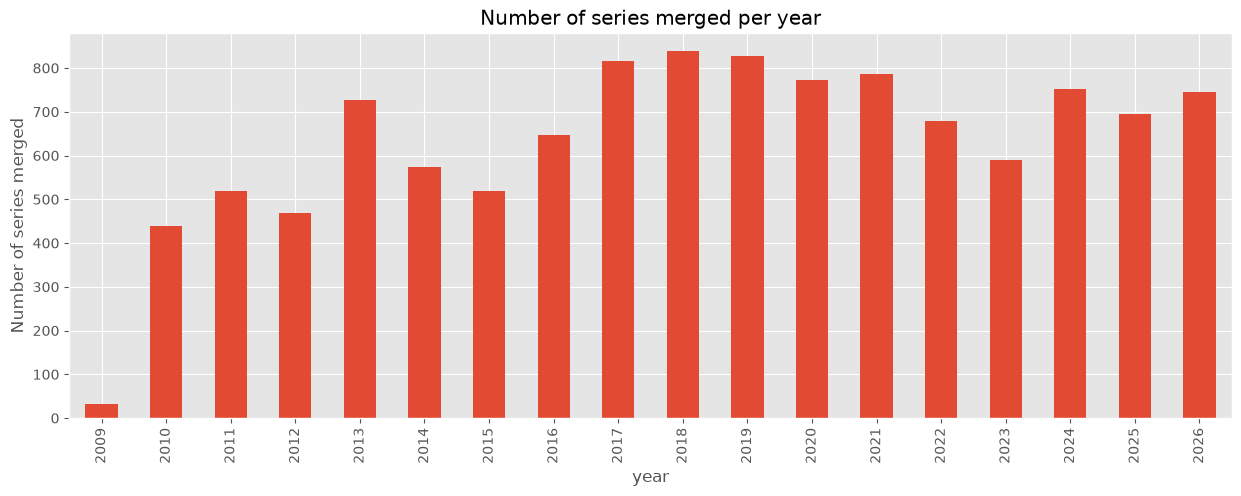

In [12]:
num_series_merged = (
    df[['merge_time', 'time_to_merge']]
        .groupby(df.merge_time.dt.year)
        .aggregate('time_to_merge')
        .count())
num_series_merged.plot(kind='bar', title="Number of series merged per year", ylabel='Number of series merged', xlabel='year')

# Number of iterations

How many patch series are finished in 1 iteration (vs 2, 3, 4, 5, etc?)

<Axes: xlabel='# iterations', ylabel='# patch series'>

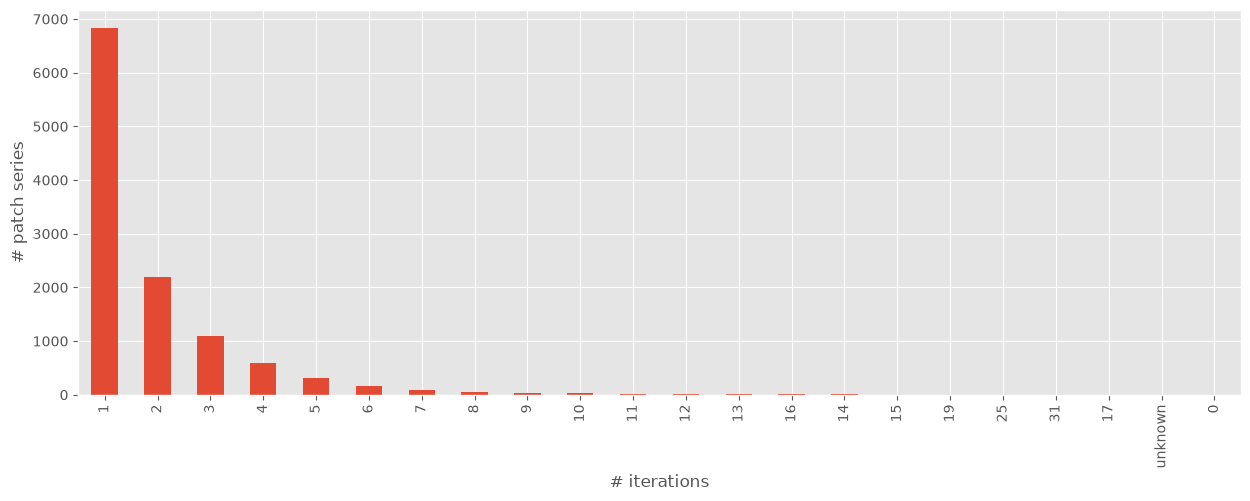

In [13]:
(df.iterations.fillna('unknown')
    .astype(str)
    .value_counts() # count values
    .plot(kind='bar', xlabel="# iterations", ylabel="# patch series")
)